<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/01-Mi-segundo-modelo-Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Mi segundo modelo
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Nombre y Apellido &bull; Fecha
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

Este cuaderno está diseñado para practicar el entrenamiento y evaluación de un modelo de regresión lineal utilizando datos reales. Los objetivos principales son:

- Entrenar un modelo de regresión lineal.
- Evaluar el ajuste del modelo.


Del conjunto de datos disponible [aquí](https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv), se desea predecir la variable `price` en función de las variables `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`.

In [23]:
# Paquetes necesarios
import numpy as np  # Para generación de datos y operaciones numéricas
import pandas as pd  # Para manejo de datos estructurados
import matplotlib.pyplot as plt  # Para visualización de datos
from sklearn.linear_model import LinearRegression  # Para el modelo de regresión lineal
from sklearn.metrics import mean_squared_error, r2_score  # Para evaluación del modelo
from sklearn.model_selection import train_test_split

---
## <font color='264CC7'> Lectura de Datos </font>


:Realiza la lectura de los datos y presenta las primeras filas del conjunto de datos.

In [ ]:
data='https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv'
# Leemos los datos con pandas
df = pd.read_csv(data)
# Escogemos aquellas columnas que son de nuestro interés para este modelo.
columnas = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'price']
df = df.loc[:, columnas]
df.head(20)

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,price
0,3,1.00,1180,5650,1.0,221900.0
1,3,2.25,2570,7242,2.0,538000.0
2,2,1.00,770,10000,1.0,180000.0
3,4,3.00,1960,5000,1.0,604000.0
4,3,2.00,1680,8080,1.0,510000.0
5,4,4.50,5420,101930,1.0,1225000.0
6,3,2.25,1715,6819,2.0,257500.0
7,3,1.50,1060,9711,1.0,291850.0
8,3,1.00,1780,7470,1.0,229500.0
9,3,2.50,1890,6560,2.0,323000.0


Separa las características y las etiquetas y mostrar la dimensión de cada elemento.

In [25]:
# Dividir el conjunto de datos en características y etiquetas
caracteristicas = ['bedrooms','bathrooms','sqft_living','sqft_lot','floors']
X = df.loc[:, caracteristicas]
y = df.loc[:, ['price']]

---
## <font color='264CC7'> Conjunto de entrenamiento y prueba </font>

Divide los datos en dos conjuntos: uno para entrenamiento y otro para prueba y visualiza la dimensión de cada conjunto. Usar `random_state` igual al último número de tu cédula.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=44)

Revisa la distribución de las etiquetas en los conjuntos de entrenamiento y prueba.

print('Conjunto de entrenamiento de prueba: \n')


Conjunto de prueba: 

X_train:  (17290, 5)
y_train: (17290, 1)
X_test:  (4323, 5)
y_test: (4323, 1)


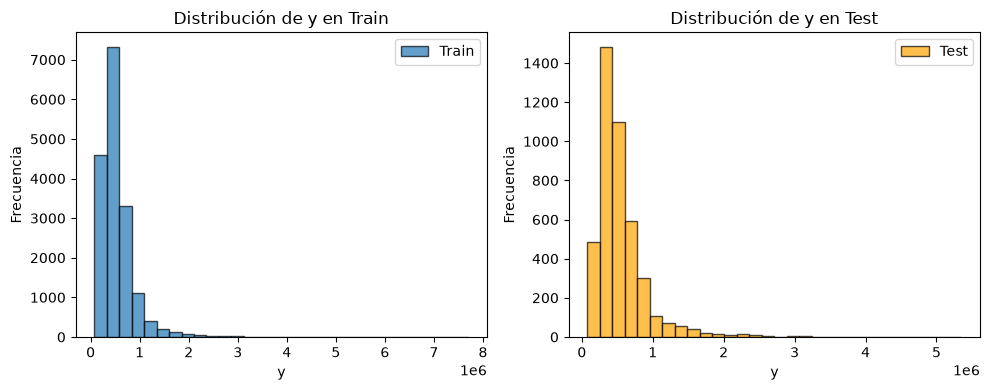

In [27]:
# .shape(filas, columnas) nos permite conocer la dimensión de los conjuntos de datos
print('Conjunto de prueba: \n')
print('X_train: ', X_train.shape)
print('y_train:', y_train.shape)
print('X_test: ', X_test.shape)
print('y_test:', y_test.shape)

# Grafico la distribución del precio en el conjunto de entrenamiento y prueba
plt.figure(figsize=(10, 4))

# Histograma para y_train
plt.subplot(1, 2, 1)
plt.hist(y_train, bins=30, alpha=0.7, edgecolor='black', label='Train')
plt.title('Distribución de y en Train')
plt.xlabel('y')
plt.ylabel('Frecuencia')
plt.legend()

# Histograma para y_test
plt.subplot(1, 2, 2)
plt.hist(y_test, bins=30, alpha=0.7, edgecolor='black', label='Test', color='orange')
plt.title('Distribución de y en Test')
plt.xlabel('y')
plt.ylabel('Frecuencia')
plt.legend()

plt.tight_layout()
plt.show()

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Decide si hace falta escalar las características para este ejemplo de regresión lineal. Si aplicas una transformación vista en clase, aprende sus parámetros solo con X_train y aplica la misma transformación a X_test, sin modificar la variable objetivo. No elijas transformaciones por su error de prueba.

In [28]:
from sklearn.preprocessing import StandardScaler

scalable_variable = StandardScaler()

X_train_scaled = scalable_variable.fit_transform(X_train)
X_test_scaled = scalable_variable.transform(X_test)

---
## <font color='264CC7'> Entrenamiento </font>

Define un modelo de regresión lineal y entrénalo con los datos de entrenamiento.

In [29]:
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 5)","[[-53008.02, 4221.79,286933.97,-13942.37, 1159.82]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[538103.98]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[208.06,132.32,120.46, 85.52, 61.88]"


---
## <font color='264CC7'> Evaluación </font>

Realiza las predicciones con el conjunto de prueba y muestra los valores en una tabla.

In [30]:
y_prediccion_precio = modelo.predict(X_test_scaled)

df_predicciones = pd.DataFrame({
    'Actual': y_test.values.flatten(),
    'Predicción': y_prediccion_precio.flatten()
})
display(df_predicciones)

,Actual,Predicción
0,430000.0,443697.367179
1,275000.0,501664.454386
2,453500.0,395176.120360
3,1651000.0,993950.793964
4,319900.0,633891.619405
...,...,...
4318,599000.0,431481.297307
4319,728000.0,516197.716782
4320,291000.0,396398.973479
4321,700000.0,847395.729336


Calcula el error cuadrático medio.

In [31]:
error_medio = mean_squared_error(y_test, y_prediccion_precio)

print('Error cuadrático medio:', error_medio)

Error cuadrático medio: 69516614855.04005


Registra las características utilizadas, la proporción de prueba, la semilla, el preprocesamiento elegido y el error cuadrático medio del modelo. Interpreta el resultado en unidades cuadradas del precio y explica sus limitaciones. No se exige comparar escalados ni elegir el que produzca el menor error de prueba.

Escribe una conclusión sobre el flujo implementado: qué aprendió el modelo de entrenamiento, qué información aporta prueba y qué deberías reservar para validación si quisieras comparar alternativas.